# Part 2: Check the estimates

Replay `traces/azure_conversation.csv` in Vidur (vLLM, one simulated A100-80GB), compare it with your Part 1 predictions, then look at what Part 1 could not see: the time between output tokens. Run from the repo root:

```bash
QPS=5.53 bash scripts/run_default.sh traces/azure_conversation.csv
```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "traces").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.replay import load_run
from analysis.workload import kv_in_use, load_trace, predict_queue_wait

WAIT_TARGET_S = 2.0    # P99 wait under 2 s (Part 1)
TBT_TARGET_S = 0.100   # P99 time between tokens under 100 ms
BIN_S = 30.0

trace = load_trace(ROOT / "traces" / "azure_conversation.csv")
predicted_wait = predict_queue_wait(trace)
predicted_kv = kv_in_use(trace, predicted_wait, BIN_S)

RUN = ROOT / "simulator_output" / "2026-10-25_23-06-57-910635"   # your vLLM run
run = load_run(RUN, trace)
req, kv = run["requests"], run["kv"]

## Predicted vs measured

                                 predicted         Vidur
P99 wait (s)                          72.1         128.8
longest stretch above 2 s      1192-2272 s   1340-2491 s
requests waiting over 2 s              36%           41%
peak KV cache (GiB)                   26.7          23.8


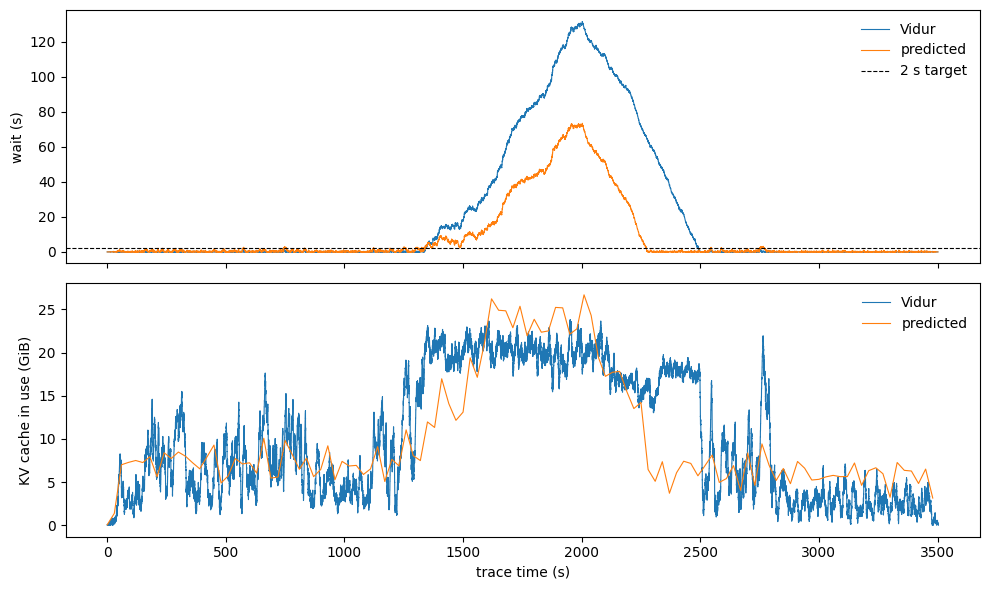

In [2]:
t = req.arrived_at.to_numpy()

def longest_late_stretch(wait, merge_gap_s=60.0):
    """Longest time range where requests wait over the target (gaps under a minute merged)."""
    late = t[wait > WAIT_TARGET_S]
    if len(late) == 0:
        return "never"
    breaks = np.flatnonzero(np.diff(late) > merge_gap_s)
    starts, ends = np.r_[late[0], late[breaks + 1]], np.r_[late[breaks], late[-1]]
    i = np.argmax(ends - starts)
    return f"{starts[i]:.0f}-{ends[i]:.0f} s"

print(f"{'':28s}{'predicted':>14s}{'Vidur':>14s}")
print(f"{'P99 wait (s)':28s}{np.quantile(predicted_wait, .99):14.1f}{req.wait.quantile(.99):14.1f}")
print(f"{'longest stretch above 2 s':28s}{longest_late_stretch(predicted_wait):>14s}{longest_late_stretch(req.wait.to_numpy()):>14s}")
print(f"{'requests waiting over 2 s':28s}{np.mean(predicted_wait > WAIT_TARGET_S):14.0%}{np.mean(req.wait > WAIT_TARGET_S):14.0%}")
print(f"{'peak KV cache (GiB)':28s}{predicted_kv.kv_gib.max():14.1f}{kv.kv_gib.max():14.1f}")

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax0.plot(t, req.wait, label="Vidur", linewidth=0.8)
ax0.plot(t, predicted_wait, label="predicted", linewidth=0.8)
ax0.axhline(WAIT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="2 s target")
ax0.set_ylabel("wait (s)")
ax0.legend(frameon=False)
ax1.plot(kv.time, kv.kv_gib, label="Vidur", linewidth=0.8)
ax1.plot(predicted_kv.bin_start, predicted_kv.kv_gib, label="predicted", linewidth=0.8)
ax1.set_ylabel("KV cache in use (GiB)")
ax1.set_xlabel("trace time (s)")
ax1.legend(frameon=False)
fig.tight_layout()
plt.show()

## Time between tokens

time between tokens: P50 17 ms   P90 131 ms   P99 563 ms   longest 6.6 s


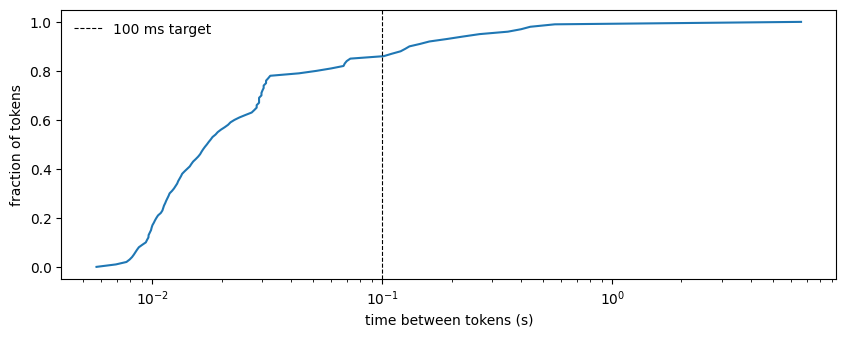

In [3]:
tbt = run["tbt"].set_index("percentile").seconds
print(f"time between tokens: P50 {tbt[50]*1e3:.0f} ms   P90 {tbt[90]*1e3:.0f} ms   P99 {tbt[99]*1e3:.0f} ms   longest {tbt[100]:.1f} s")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tbt.to_numpy(), tbt.index / 100)
ax.axvline(TBT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="100 ms target")
ax.set_xscale("log")
ax.set_xlabel("time between tokens (s)")
ax.set_ylabel("fraction of tokens")
ax.legend(frameon=False)
plt.show()

## Questions

**Q1.** Compare your Part 1 predictions with Vidur: P99 wait, the longest stretch above the 2 s target, and peak KV-cache memory. Which held and which did not? For any that missed, say what the Part 1 model left out.

**Your answer:**

**Held:** where and roughly how long the overload is. Both the prediction and Vidur stay near or under the 2 s target until the surge (about t = 1192 s predicted, 1340 s measured), then spend one long stretch above it (1080 s predicted, 1152 s measured). Both put the peak KV memory in the surge (2010 s vs 1952 s).

**Missed:** how bad the queue gets and when it clears. P99 wait is predicted at 72.1 s but Vidur measures 128.8 s (1.8x higher), and the stretch above the target ends about 219 s later than predicted. The peak KV estimate is 12% too high (26.7 vs 23.8 GiB). Neither meets the 2 s target: 40.7% of requests wait over 2 s in Vidur, though the median wait is only 0.20 s.

**What the Part 1 model left out:**
- **Real throughput is below the best case.** The model uses best-case rates (12,000 prompt tokens/s, 4,267 output tokens/s, a full batch of 128). By those rates the trace needs 2,799 s of work, 80% of its 3,502 s. In Vidur the GPU was busy 99.75% of the run (about 3,495 s), roughly 25% more work. Decode batches are often not full (median batch 20 requests, 90th percentile 74), so 30 ms per 128 tokens is an upper bound.
- **vLLM stalls decoding behind prompts.** Iterations that carry whole prompts (up to about 4,000 tokens) run up to 365 ms, and nothing decodes during them. The model has no such interference.
- **Queues amplify small errors near saturation.** About a quarter more work than assumed, in a system already overloaded for about 19 minutes, becomes a wait almost twice as long.
- **Memory is allocated differently.** Part 1 reserves a request's prompt plus full output from arrival, even while it queues. Vidur allocates 16-token blocks only once a request starts and adds them as tokens are produced, so waiting requests hold nothing. Vidur's peak was 40.4% of its block budget with zero restarts, so memory never limited scheduling.


**Q2.** The target for time between tokens is **P99 under 100 ms**. Does vLLM meet it? Report the P50, P99, and longest time between tokens. What does the longest one mean for a user reading the answer?

**Your answer:**

**No.** P50 is **17 ms**, P90 131 ms, P99 **563 ms** (5.6x the target), and the longest gap is **6.6 s**. About 86% of gaps are under 100 ms, so the typical token is fast and the problem is the tail.

For a user, the longest gap means the text stops mid-stream and nothing arrives for 6.6 seconds, which looks like a hang. The median gap (17 ms) hides this, yet 1 in 100 tokens waits more than half a second.


**Q3.** What causes the longest gaps between tokens you found in Q2? Read `_get_next_batch` in `vidur/scheduler/replica_scheduler/vllm_replica_scheduler.py`: when new requests are waiting, what goes into the next iteration, and what has to wait?

**Your answer:**

In `_get_next_batch`, vLLM first loops over `self._request_queue`, the requests that have not started. Each one that fits (KV memory, `batch_size_cap` of 128, and the `max_tokens_in_batch` of 4,096 check) is added with its **entire prompt** as its token count. Only if that loop adds nothing (`if requests:` is false) does it turn to `self._preempted_requests`, the requests already running and mid-answer.

So whenever a new request is waiting and fits, the next iteration is made of whole prompts and **every decoding request is left out of it**; those requests wait out the whole iteration before they get another token. A batch of prompts totalling about 4,000 tokens takes about 365 ms (the 99th-percentile batch time is 365 ms against an 11 ms median). During the surge the waiting queue never empties, so one prompt iteration is followed by another and decoders can be skipped many times in a row. A 6.6 s gap is consistent with about 18 such iterations back to back.


**Q4.** Part 3 fixes this by capping each iteration at a token budget C: every running request gets its one token, and waiting prompts fill the rest of the budget in chunks. One pass with C tokens (decode and prompt tokens together) takes about **6 ms + C × 78 µs** (Vidur's measured prefill time). Predict the P99 time between tokens for C = 256, 512, and 2048. Which meet the 100 ms target? What happens to the fixed 6 ms per pass, and so to throughput and the queue, when the same prompts take more passes?

| C | Predicted P99 time between tokens |
|---|---|
| 256 | 26.0 ms (meets) |
| 512 | 45.9 ms (meets) |
| 2048 | 165.7 ms (misses) |

**Your answer:**

With budget C, every running request gets its one token each pass, so the gap between tokens is about the pass time, 6 ms + C × 78 µs: **26.0 ms** at C = 256, **45.9 ms** at C = 512, **165.7 ms** at C = 2048. **C = 256 and 512 meet the 100 ms target; 2048 does not.**

The fixed 6 ms is paid once per pass, whatever its size. Smaller chunks mean more passes for the same prompts (a typical 1,140-token prompt takes 5 passes at C = 256, 3 at 512, 1 at 2048), so more of each second goes to the fixed cost. Throughput C / (6 ms + C × 78 µs) falls as C shrinks: about 9,860 tokens/s at 256, 11,150 at 512, 12,360 at 2048 (ceiling 1 / 78 µs, about 12,820). The queue then drains more slowly and waits grow: smaller C buys smoother streaming at the price of a longer queue.
